In [2]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
import statsmodels.formula.api as smf
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from patsy import dmatrix
from scipy import stats
import warnings; warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
RNG = np.random.default_rng(42)

df = pd.read_csv('../dataset/abide_merged.csv').replace(-9999, np.nan)
THICK = [c for c in df.columns if c.startswith(('lh_','rh_'))]
df = df.dropna(subset=THICK+['AGE_AT_SCAN','SEX','DX_GROUP']).reset_index(drop=True)
df['DX_LABEL'] = df.DX_GROUP.map({1:'ASD',2:'Control'})
df['age_c'] = df.AGE_AT_SCAN - df.AGE_AT_SCAN.mean()
df['mean_thick'] = df[THICK].mean(axis=1)              # global covariate
df['FIQ_imp'] = df.groupby('SITE_ID')['FIQ'].transform(lambda s: s.fillna(s.median()))
df['FIQ_imp'] = df['FIQ_imp'].fillna(df['FIQ'].median())

CONFIRMED = ['rh_superiorfrontal','lh_superiorfrontal','rh_caudalmiddlefrontal',
             'lh_transversetemporal','rh_rostralmiddlefrontal','lh_precuneus',
             'lh_entorhinal','rh_superiorparietal','rh_inferiorparietal','lh_lingual']
print(f'N={len(df)} | ASD={int((df.DX_GROUP==1).sum())} Ctrl={int((df.DX_GROUP==2).sum())}')

N=1027 | ASD=499 Ctrl=528



Cell 2 — Model diagnostics on the 10 confirmed regions

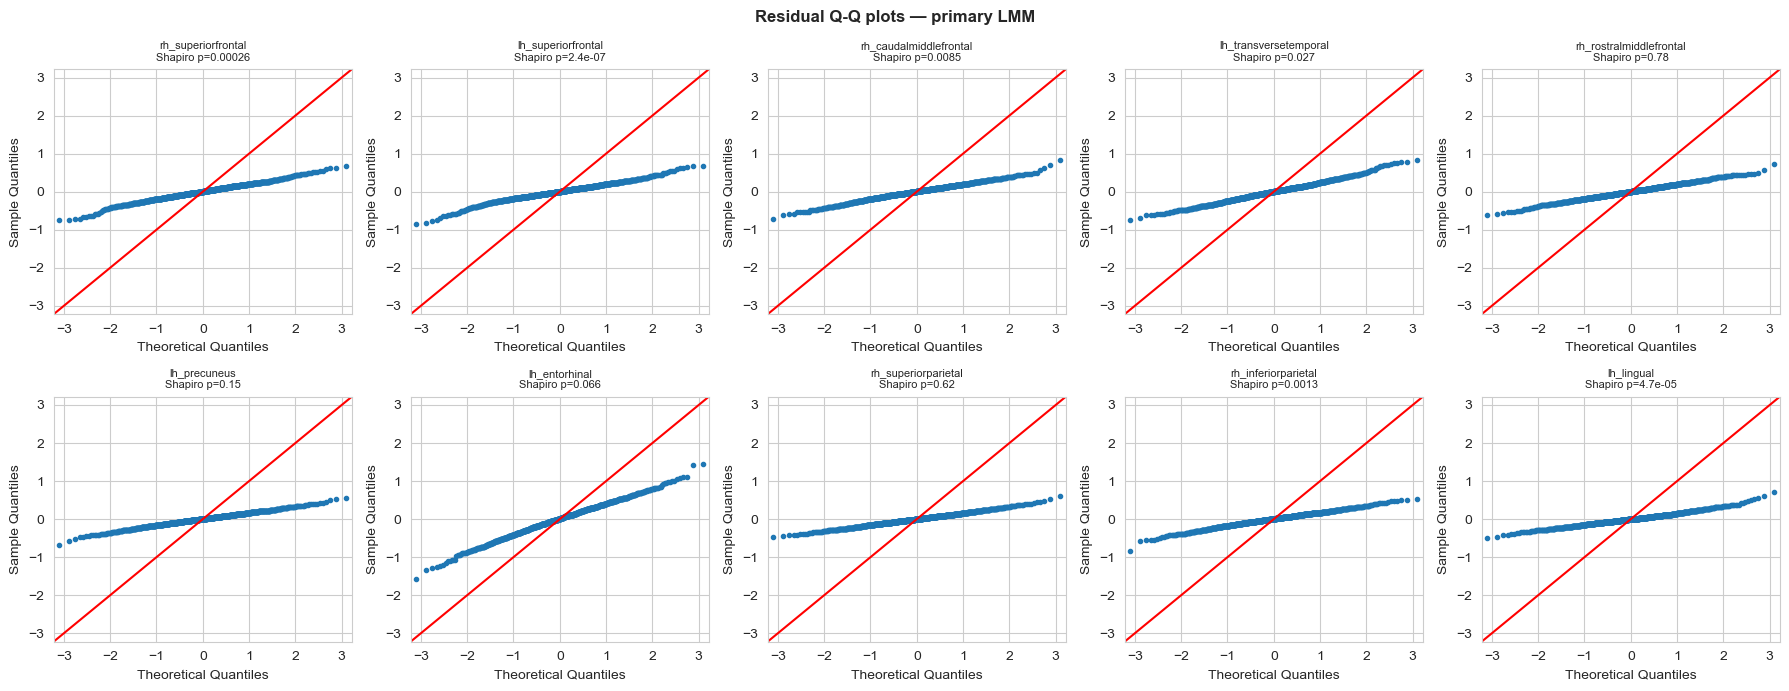

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(18,7))
for ax, reg in zip(axes.ravel(), CONFIRMED):
    d = df[['DX_GROUP','age_c','SEX','SITE_ID']].copy(); d['y'] = df[reg].values
    r = smf.mixedlm('y ~ C(DX_GROUP)*age_c + C(SEX)', d, groups=d.SITE_ID).fit(reml=True, method='lbfgs')
    res = r.resid
    sm.qqplot(res, line='45', ax=ax, markersize=3)
    sw = stats.shapiro(res[:min(5000,len(res))])[1]
    ax.set_title(f'{reg}\nShapiro p={sw:.2g}', fontsize=8)
plt.suptitle('Residual Q-Q plots — primary LMM', fontweight='bold'); plt.tight_layout()
plt.savefig('rq5b_qq.png', dpi=120); plt.show()

Cell 3 — Refit with FIQ + global thickness covariates

In [4]:
def fit_lmm(data, formula, regions):
    out = []
    for reg in regions:
        d = data.copy(); d['y'] = data[reg].values
        try:
            r = smf.mixedlm(formula, d, groups=d.SITE_ID).fit(reml=True, method='lbfgs')
            it = [p for p in r.params.index if ':age_c' in p and 'DX_GROUP' in p][0]
            out.append(dict(region=reg, beta=r.params[it], se=r.bse[it], p=r.pvalues[it]))
        except Exception as e:
            out.append(dict(region=reg, beta=np.nan, se=np.nan, p=np.nan))
    res = pd.DataFrame(out)
    res['q'] = multipletests(res.p.fillna(1), method='fdr_bh')[1]
    res['sig'] = res.q < 0.05
    return res

base = fit_lmm(df, 'y ~ C(DX_GROUP)*age_c + C(SEX)', CONFIRMED)
fiq  = fit_lmm(df, 'y ~ C(DX_GROUP)*age_c + C(SEX) + FIQ_imp', CONFIRMED)
glb  = fit_lmm(df, 'y ~ C(DX_GROUP)*age_c + C(SEX) + mean_thick', CONFIRMED)
both = fit_lmm(df, 'y ~ C(DX_GROUP)*age_c + C(SEX) + FIQ_imp + mean_thick', CONFIRMED)

cmp = base[['region','beta','q']].rename(columns={'beta':'b_base','q':'q_base'})
for tag, r in [('fiq',fiq),('glb',glb),('both',both)]:
    cmp[f'b_{tag}'] = r.beta.values; cmp[f'q_{tag}'] = r.q.values
print(cmp.round(4).to_string(index=False))
print('\nSurvives FIQ:',int(fiq.sig.sum()),'| global:',int(glb.sig.sum()),'| both:',int(both.sig.sum()))

                 region  b_base  q_base   b_fiq  q_fiq   b_glb  q_glb  b_both  q_both
     rh_superiorfrontal -0.0063  0.0013 -0.0063 0.0015 -0.0030 0.1130 -0.0030  0.1019
     lh_superiorfrontal -0.0056  0.0030 -0.0055 0.0041 -0.0022 0.1130 -0.0022  0.1249
 rh_caudalmiddlefrontal -0.0053  0.0030 -0.0052 0.0044 -0.0023 0.1130 -0.0022  0.1249
  lh_transversetemporal -0.0060  0.0038 -0.0059 0.0050 -0.0032 0.1130 -0.0032  0.1249
rh_rostralmiddlefrontal -0.0047  0.0038 -0.0046 0.0050 -0.0019 0.1630 -0.0019  0.1545
           lh_precuneus -0.0041  0.0038 -0.0040 0.0050 -0.0012 0.2214 -0.0012  0.2300
          lh_entorhinal -0.0100  0.0038 -0.0097 0.0050 -0.0054 0.1130 -0.0053  0.1249
    rh_superiorparietal -0.0037  0.0040 -0.0036 0.0054 -0.0014 0.2102 -0.0013  0.2300
    rh_inferiorparietal -0.0042  0.0040 -0.0041 0.0054 -0.0012 0.2346 -0.0012  0.2474
             lh_lingual -0.0036  0.0041 -0.0035 0.0054 -0.0021 0.1130 -0.0021  0.1249

Survives FIQ: 10 | global: 0 | both: 0


Cell 4 — Random slopes for site

In [5]:
rows = []
for reg in CONFIRMED:
    d = df[['DX_GROUP','age_c','SEX','SITE_ID']].copy(); d['y'] = df[reg].values
    try:
        r = smf.mixedlm('y ~ C(DX_GROUP)*age_c + C(SEX)', d, groups=d.SITE_ID,
                        re_formula='~age_c').fit(reml=True, method='lbfgs')
        it = [p for p in r.params.index if ':age_c' in p and 'DX_GROUP' in p][0]
        rows.append(dict(region=reg, beta=r.params[it], p=r.pvalues[it], conv=r.converged))
    except Exception:
        rows.append(dict(region=reg, beta=np.nan, p=np.nan, conv=False))
rs = pd.DataFrame(rows); rs['q'] = multipletests(rs.p.fillna(1),method='fdr_bh')[1]
print(rs.round(4).to_string(index=False))
print(f'\nSurvive with random slopes: {int((rs.q<0.05).sum())}/10')

                 region    beta      p  conv      q
     rh_superiorfrontal -0.0060 0.0003  True 0.0026
     lh_superiorfrontal -0.0053 0.0012  True 0.0059
 rh_caudalmiddlefrontal -0.0046 0.0039  True 0.0089
  lh_transversetemporal -0.0061 0.0021  True 0.0071
rh_rostralmiddlefrontal -0.0037 0.0138  True 0.0179
           lh_precuneus -0.0032 0.0143  True 0.0179
          lh_entorhinal -0.0096 0.0045 False 0.0089
    rh_superiorparietal -0.0026 0.0339  True 0.0339
    rh_inferiorparietal -0.0033 0.0173  True 0.0192
             lh_lingual -0.0030 0.0141  True 0.0179

Survive with random slopes: 10/10


Cell 5 — Non-linear age: quadratic and natural cubic splines (LRT)

In [15]:
def lrt(reg, full_formula, null_formula):
    d = df.copy(); d['y'] = df[reg].values
    f = smf.mixedlm(full_formula, d, groups=d.SITE_ID).fit(reml=False, method='lbfgs')
    n = smf.mixedlm(null_formula, d, groups=d.SITE_ID).fit(reml=False, method='lbfgs')
    chi = 2*(f.llf - n.llf); k = f.df_modelwc - n.df_modelwc
    return chi, k, stats.chi2.sf(chi, df=max(int(k),1))

quad_rows, spl_rows = [], []
for reg in CONFIRMED:
    # quadratic: does adding age² × DX improve fit beyond linear interaction?
    chi,k,p = lrt(reg,
        'y ~ C(DX_GROUP)*age_c + C(DX_GROUP)*I(age_c**2) + C(SEX)',
        'y ~ C(DX_GROUP)*age_c + C(SEX)')
    quad_rows.append(dict(region=reg, chi2=chi, p=p))
    # spline: 4-knot natural cubic spline by group vs parallel splines
    chi,k,p = lrt(reg,
        'y ~ cr(age_c, df=4)*C(DX_GROUP) + C(SEX)',
        'y ~ cr(age_c, df=4) + C(DX_GROUP) + C(SEX)')
    spl_rows.append(dict(region=reg, chi2=chi, p=p))
# (in Cell 5, replace the last lines)
quad_df = pd.DataFrame(quad_rows); quad_df['q']=multipletests(quad_df.p,method='fdr_bh')[1]
spl_df  = pd.DataFrame(spl_rows);  spl_df['q']=multipletests(spl_df.p,method='fdr_bh')[1]
print('=== Quadratic × DX ==='); print(quad_df.round(4).to_string(index=False))
print('\n=== Spline × DX ==='); print(spl_df.round(4).to_string(index=False))

=== Quadratic × DX ===
                 region     chi2      p      q
     rh_superiorfrontal  42.1409 0.0000 0.0000
     lh_superiorfrontal  38.5242 0.0000 0.0000
 rh_caudalmiddlefrontal  34.3081 0.0000 0.0000
  lh_transversetemporal   7.1055 0.0286 0.0318
rh_rostralmiddlefrontal  88.8415 0.0000 0.0000
           lh_precuneus 118.2762 0.0000 0.0000
          lh_entorhinal   4.5428 0.1032 0.1032
    rh_superiorparietal 136.9815 0.0000 0.0000
    rh_inferiorparietal  99.8492 0.0000 0.0000
             lh_lingual  64.5574 0.0000 0.0000

=== Spline × DX ===
                 region    chi2      p      q
     rh_superiorfrontal 15.9727 0.0031 0.0153
     lh_superiorfrontal 13.9959 0.0073 0.0244
 rh_caudalmiddlefrontal 12.9768 0.0114 0.0285
  lh_transversetemporal  7.3974 0.1163 0.1939
rh_rostralmiddlefrontal 11.8302 0.0187 0.0373
           lh_precuneus  5.2486 0.2627 0.3249
          lh_entorhinal 16.0090 0.0030 0.0153
    rh_superiorparietal  5.3127 0.2567 0.3249
    rh_inferiorparietal  

Cell 6 — Three-way: sex × diagnosis × age

In [7]:
rows=[]
for reg in CONFIRMED:
    d = df.copy(); d['y']=df[reg].values
    r = smf.mixedlm('y ~ C(DX_GROUP)*age_c*C(SEX)', d, groups=d.SITE_ID).fit(reml=True,method='lbfgs')
    it = [p for p in r.params.index if 'C(DX_GROUP)' in p and 'age_c' in p and 'C(SEX)' in p]
    rows.append(dict(region=reg, term=it[0] if it else '',
                     beta=r.params[it[0]] if it else np.nan,
                     p=r.pvalues[it[0]] if it else np.nan))
tw = pd.DataFrame(rows); tw['q']=multipletests(tw.p.fillna(1),method='fdr_bh')[1]
print(tw.round(4).to_string(index=False))
print(f'\n3-way sex×dx×age significant: {int((tw.q<0.05).sum())}/10')

                 region                               term    beta      p      q
     rh_superiorfrontal C(DX_GROUP)[T.2]:age_c:C(SEX)[T.2] -0.0007 0.8960 0.9468
     lh_superiorfrontal C(DX_GROUP)[T.2]:age_c:C(SEX)[T.2]  0.0019 0.7290 0.9468
 rh_caudalmiddlefrontal C(DX_GROUP)[T.2]:age_c:C(SEX)[T.2] -0.0024 0.6510 0.9468
  lh_transversetemporal C(DX_GROUP)[T.2]:age_c:C(SEX)[T.2]  0.0047 0.4700 0.9468
rh_rostralmiddlefrontal C(DX_GROUP)[T.2]:age_c:C(SEX)[T.2] -0.0051 0.3121 0.9468
           lh_precuneus C(DX_GROUP)[T.2]:age_c:C(SEX)[T.2]  0.0045 0.3059 0.9468
          lh_entorhinal C(DX_GROUP)[T.2]:age_c:C(SEX)[T.2] -0.0092 0.4016 0.9468
    rh_superiorparietal C(DX_GROUP)[T.2]:age_c:C(SEX)[T.2]  0.0003 0.9468 0.9468
    rh_inferiorparietal C(DX_GROUP)[T.2]:age_c:C(SEX)[T.2] -0.0014 0.7774 0.9468
             lh_lingual C(DX_GROUP)[T.2]:age_c:C(SEX)[T.2] -0.0018 0.6651 0.9468

3-way sex×dx×age significant: 0/10


Cell 7 — Leave-one-site-out stability

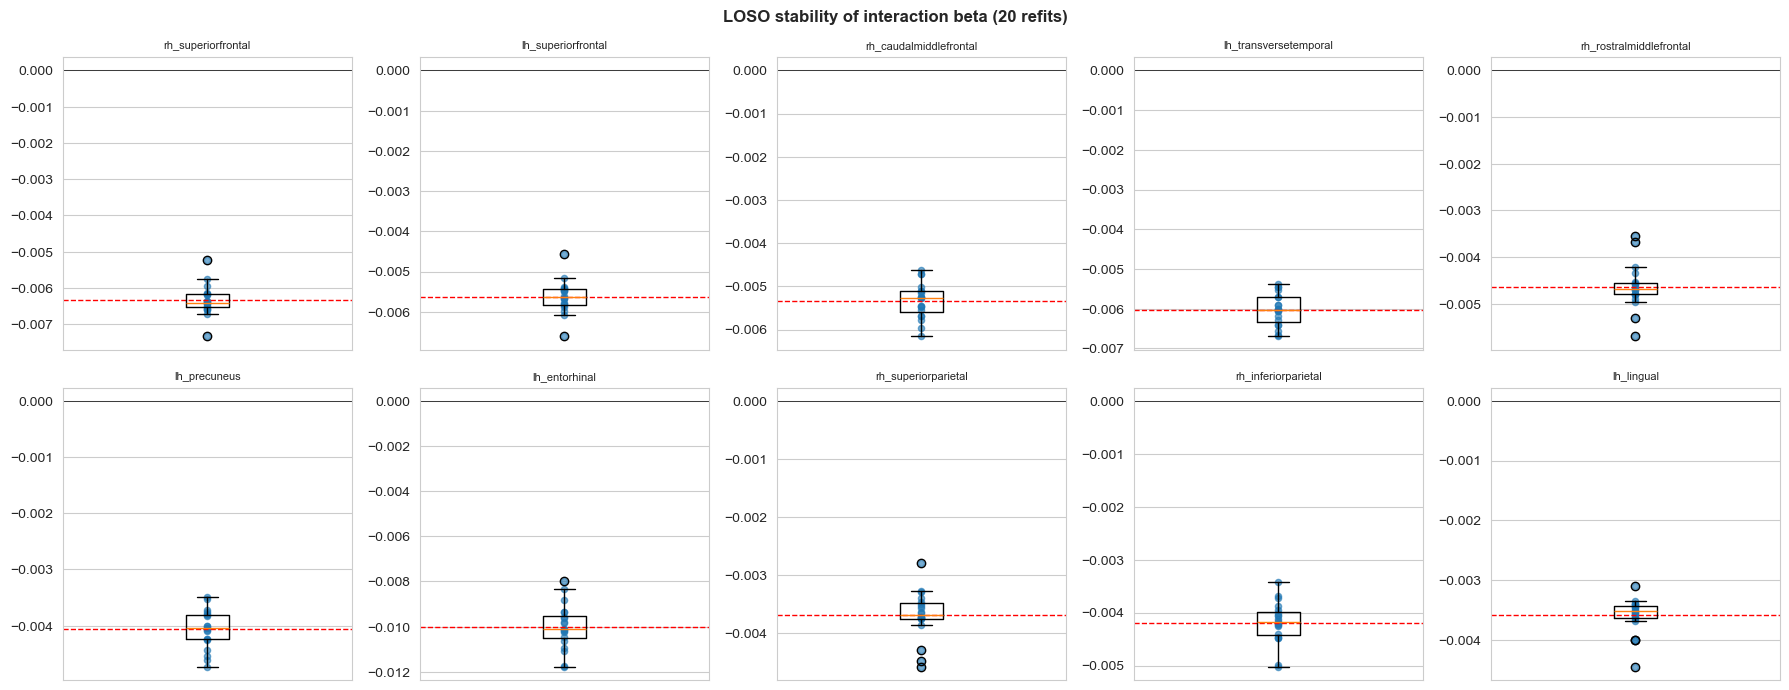

                 region     mean      sd  sign_flips
     rh_superiorfrontal -0.00634 0.00040           0
     lh_superiorfrontal -0.00562 0.00039           0
 rh_caudalmiddlefrontal -0.00534 0.00040           0
  lh_transversetemporal -0.00602 0.00039           0
rh_rostralmiddlefrontal -0.00464 0.00046           0
           lh_precuneus -0.00406 0.00033           0
          lh_entorhinal -0.01000 0.00097           0
    rh_superiorparietal -0.00369 0.00040           0
    rh_inferiorparietal -0.00419 0.00038           0
             lh_lingual -0.00359 0.00028           0


In [8]:
sites = df.SITE_ID.unique()
loso = {reg: [] for reg in CONFIRMED}
for s in sites:
    sub = df[df.SITE_ID != s]
    for reg in CONFIRMED:
        d = sub.copy(); d['y']=sub[reg].values
        try:
            r = smf.mixedlm('y ~ C(DX_GROUP)*age_c + C(SEX)', d, groups=d.SITE_ID).fit(reml=True,method='lbfgs')
            it = [p for p in r.params.index if ':age_c' in p and 'DX_GROUP' in p][0]
            loso[reg].append((s, r.params[it], r.pvalues[it]))
        except: loso[reg].append((s, np.nan, np.nan))

fig, axes = plt.subplots(2,5,figsize=(18,7),sharey=False)
for ax,reg in zip(axes.ravel(),CONFIRMED):
    betas = [b for _,b,_ in loso[reg]]
    ax.axhline(0,color='k',lw=0.5); ax.axhline(np.mean(betas),color='red',ls='--',lw=1)
    ax.boxplot(betas, vert=True); ax.scatter([1]*len(betas), betas, alpha=0.6, s=20)
    ax.set_title(reg, fontsize=8); ax.set_xticks([])
plt.suptitle('LOSO stability of interaction beta (20 refits)', fontweight='bold')
plt.tight_layout(); plt.savefig('rq5b_loso.png', dpi=120); plt.show()

stab = pd.DataFrame([{'region':r,
    'mean':np.nanmean([b for _,b,_ in loso[r]]),
    'sd':np.nanstd([b for _,b,_ in loso[r]]),
    'sign_flips':sum(np.sign(b)!=np.sign(np.nanmean([b2 for _,b2,_ in loso[r]]))
                     for _,b,_ in loso[r] if not np.isnan(b))} for r in CONFIRMED])
print(stab.round(5).to_string(index=False))

Cell 8 — Bootstrap CIs on slope difference (cluster-resampled by site)

Bootstrapping (500 iter per region, ~minutes)...
                 region      lo     med      hi  excludes_zero
     rh_superiorfrontal 0.00280 0.00562 0.00987           True
     lh_superiorfrontal 0.00290 0.00570 0.00950           True
 rh_caudalmiddlefrontal 0.00220 0.00582 0.00999           True
  lh_transversetemporal 0.00141 0.00624 0.00968           True
rh_rostralmiddlefrontal 0.00129 0.00406 0.00780           True
           lh_precuneus 0.00109 0.00380 0.00668           True
          lh_entorhinal 0.00454 0.01198 0.02016           True
    rh_superiorparietal 0.00061 0.00434 0.00716           True
    rh_inferiorparietal 0.00153 0.00508 0.00827           True
             lh_lingual 0.00053 0.00380 0.00698           True


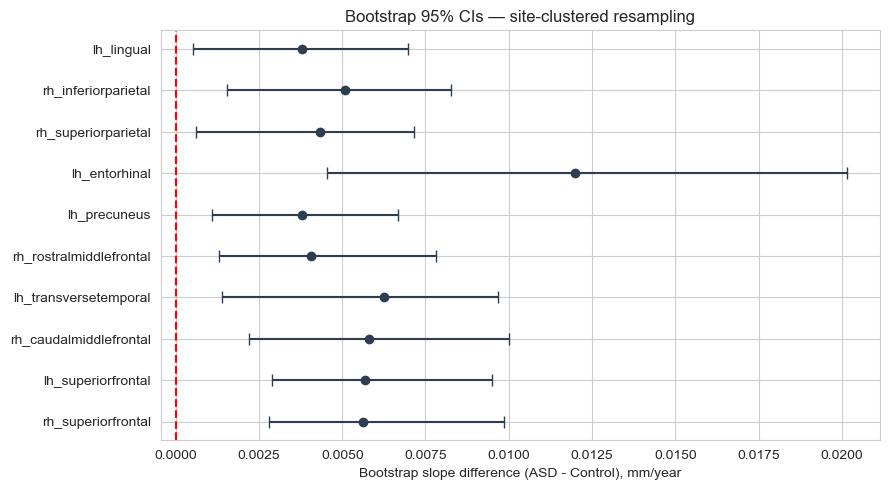

In [9]:
def boot_slope_diff(reg, n_boot=500):
    d0 = df[['DX_GROUP','age_c','SEX','SITE_ID']].copy(); d0['y']=df[reg].values
    diffs=[]
    sites = d0.SITE_ID.unique()
    for _ in range(n_boot):
        bs = RNG.choice(sites, size=len(sites), replace=True)
        boot = pd.concat([d0[d0.SITE_ID==s] for s in bs], ignore_index=True)
        boot['SITE_ID'] = boot['SITE_ID'].astype(str)+'_'+boot.groupby('SITE_ID').cumcount().astype(str).str[:1]
        try:
            r = smf.mixedlm('y ~ C(DX_GROUP)*age_c + C(SEX)', boot, groups=boot.SITE_ID).fit(reml=True,method='lbfgs')
            it = [p for p in r.params.index if ':age_c' in p and 'DX_GROUP' in p][0]
            diffs.append(-r.params[it])   # slope_diff = ASD - Control = -interaction (DX=2 reference flip)
        except: pass
    return np.percentile(diffs, [2.5, 50, 97.5]) if diffs else (np.nan,)*3

print('Bootstrapping (500 iter per region, ~minutes)...')
boot_res = []
for reg in CONFIRMED:
    lo, med, hi = boot_slope_diff(reg, n_boot=500)
    boot_res.append(dict(region=reg, lo=lo, med=med, hi=hi, excludes_zero=(lo>0 or hi<0)))
br = pd.DataFrame(boot_res); print(br.round(5).to_string(index=False))

fig, ax = plt.subplots(figsize=(9,5))
y = np.arange(len(br)); ax.errorbar(br.med, y, xerr=[br.med-br.lo, br.hi-br.med],
    fmt='o', color='#2c3e50', capsize=4)
ax.axvline(0, color='red', ls='--'); ax.set_yticks(y); ax.set_yticklabels(br.region)
ax.set_xlabel('Bootstrap slope difference (ASD - Control), mm/year')
ax.set_title('Bootstrap 95% CIs — site-clustered resampling')
plt.tight_layout(); plt.savefig('rq5b_bootstrap.png', dpi=120); plt.show()

Cell 9 — Predicted trajectories with CI ribbons + age of max divergence

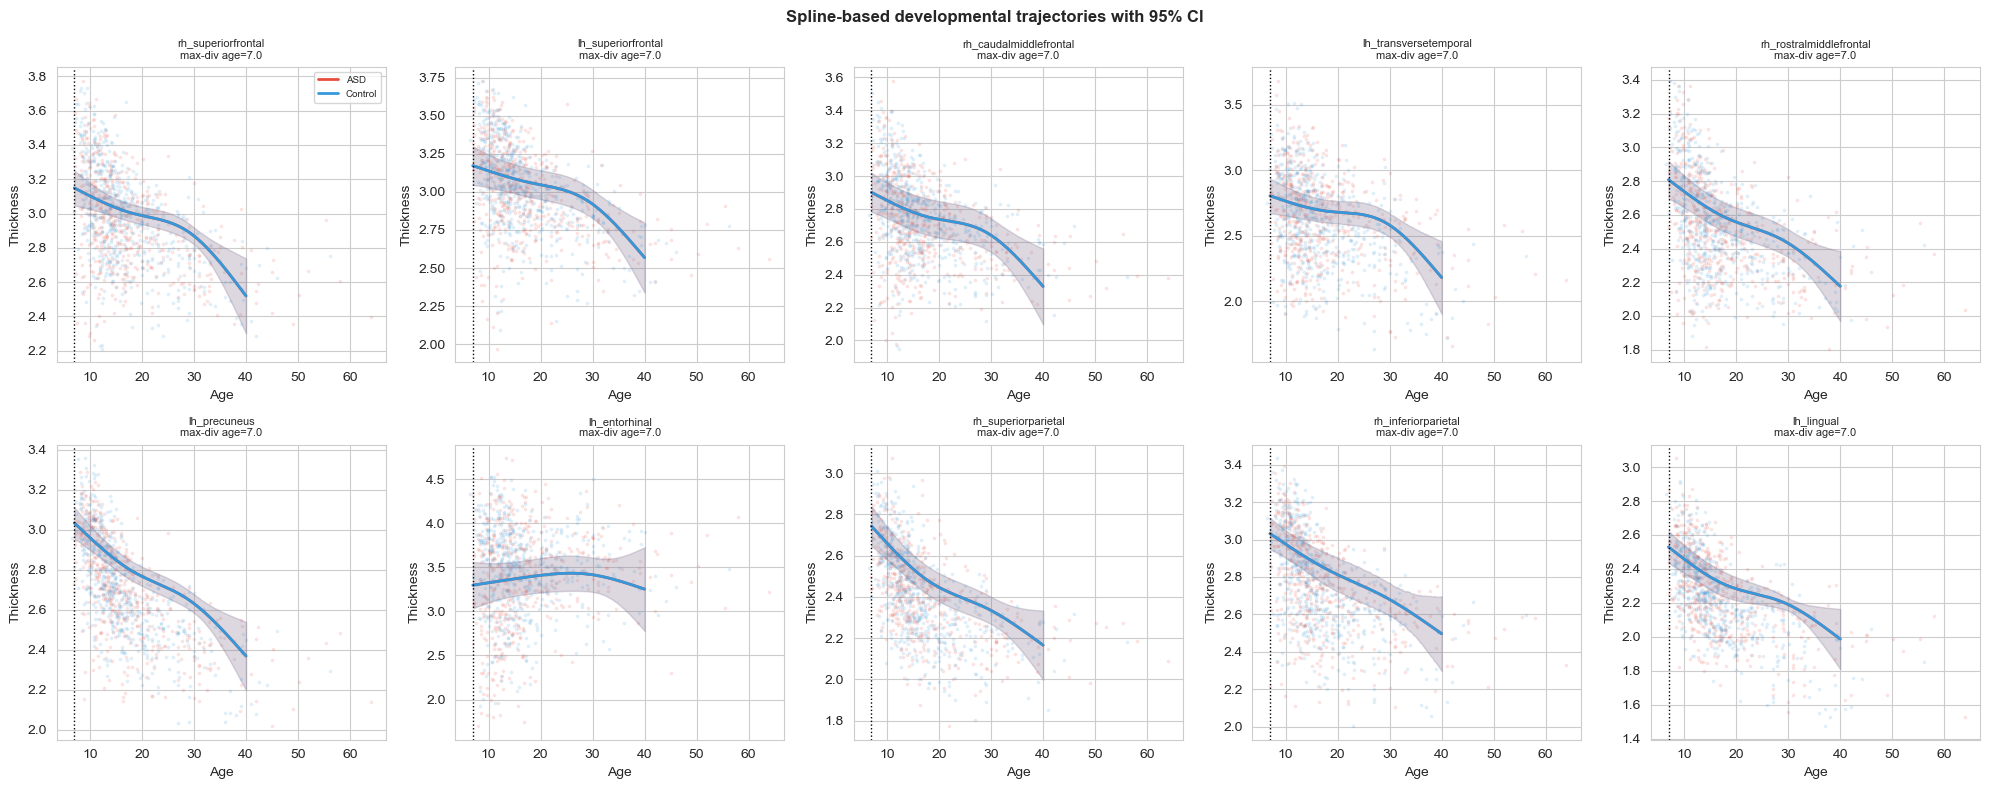

                 region  age_max_div  max_diff_mm
     rh_superiorfrontal          7.0          0.0
     lh_superiorfrontal          7.0          0.0
 rh_caudalmiddlefrontal          7.0          0.0
  lh_transversetemporal          7.0          0.0
rh_rostralmiddlefrontal          7.0          0.0
           lh_precuneus          7.0          0.0
          lh_entorhinal          7.0          0.0
    rh_superiorparietal          7.0          0.0
    rh_inferiorparietal          7.0          0.0
             lh_lingual          7.0          0.0


In [10]:
ages = np.linspace(7, 40, 200)
divergence = []
fig, axes = plt.subplots(2,5,figsize=(20,8))
for ax,reg in zip(axes.ravel(),CONFIRMED):
    d = df.copy(); d['y']=df[reg].values
    r = smf.mixedlm('y ~ cr(age_c, df=4)*C(DX_GROUP) + C(SEX)', d, groups=d.SITE_ID).fit(reml=True,method='lbfgs')
    age_c_grid = ages - df.AGE_AT_SCAN.mean()
    preds = {}
    for dx, col in [(1,'#e74c3c'),(2,'#3498db')]:
        nd = pd.DataFrame({'age_c':age_c_grid,'DX_GROUP':dx,'SEX':1,'SITE_ID':df.SITE_ID.iloc[0]})
        X = dmatrix('cr(age_c, df=4)*C(DX_GROUP) + C(SEX)', nd, return_type='dataframe')
        X = X.reindex(columns=r.params.index, fill_value=0)
        mu = X @ r.params
        se = np.sqrt(np.diag(X @ r.cov_params() @ X.T))
        preds[dx] = mu.values
        ax.fill_between(ages, mu-1.96*se, mu+1.96*se, color=col, alpha=0.15)
        ax.plot(ages, mu, color=col, lw=2, label='ASD' if dx==1 else 'Control')
        sub = df[df.DX_GROUP==dx]
        ax.scatter(sub.AGE_AT_SCAN, sub[reg], s=3, alpha=0.1, color=col)
    diff = preds[1] - preds[2]
    age_max = ages[np.argmax(np.abs(diff))]
    ax.axvline(age_max, color='k', ls=':', lw=1)
    divergence.append(dict(region=reg, age_max_div=age_max, max_diff_mm=diff[np.argmax(np.abs(diff))]))
    ax.set_title(f'{reg}\nmax-div age={age_max:.1f}', fontsize=8)
    ax.set_xlabel('Age'); ax.set_ylabel('Thickness')
    if reg==CONFIRMED[0]: ax.legend(fontsize=7)
plt.suptitle('Spline-based developmental trajectories with 95% CI', fontweight='bold')
plt.tight_layout(); plt.savefig('rq5b_trajectories.png', dpi=130); plt.show()
print(pd.DataFrame(divergence).round(3).to_string(index=False))

Cell 10 — Network-level aggregation (Yeo-7 approximation)

In [11]:
NETWORKS = {
    'Visual': ['cuneus','pericalcarine','lingual','lateraloccipital'],
    'Somatomotor': ['precentral','postcentral','paracentral','transversetemporal'],
    'DorsalAttn': ['superiorparietal','inferiorparietal','superiortemporal'],
    'VentralAttn': ['supramarginal','insula','bankssts'],
    'Limbic': ['entorhinal','parahippocampal','temporalpole','fusiform'],
    'FrontoParietal': ['rostralmiddlefrontal','caudalmiddlefrontal','parsopercularis',
                       'parstriangularis','parsorbitalis'],
    'DefaultMode': ['superiorfrontal','medialorbitofrontal','precuneus','posteriorcingulate',
                    'isthmuscingulate','middletemporal','inferiortemporal'],
}
for net, regs in NETWORKS.items():
    cols = [f'{h}_{r}' for h in ['lh','rh'] for r in regs if f'{h}_{r}' in df.columns]
    df[f'net_{net}'] = df[cols].mean(axis=1)

rows=[]
for net in NETWORKS:
    d = df.copy(); d['y']=df[f'net_{net}'].values
    r = smf.mixedlm('y ~ C(DX_GROUP)*age_c + C(SEX)', d, groups=d.SITE_ID).fit(reml=True,method='lbfgs')
    it = [p for p in r.params.index if ':age_c' in p and 'DX_GROUP' in p][0]
    rows.append(dict(network=net, beta=r.params[it], se=r.bse[it], p=r.pvalues[it]))
net_res = pd.DataFrame(rows); net_res['q']=multipletests(net_res.p,method='fdr_bh')[1]
print(net_res.round(4).to_string(index=False))

       network    beta     se      p      q
        Visual -0.0021 0.0011 0.0502 0.0586
   Somatomotor -0.0024 0.0011 0.0244 0.0382
    DorsalAttn -0.0025 0.0011 0.0273 0.0382
   VentralAttn -0.0021 0.0012 0.0846 0.0846
        Limbic -0.0048 0.0018 0.0094 0.0302
FrontoParietal -0.0037 0.0013 0.0033 0.0230
   DefaultMode -0.0025 0.0010 0.0129 0.0302


Cell 11 — Influence diagnostics: drop older tail and re-test

In [12]:
sens = []
for cutoff in [None, 40, 35, 30, 25]:
    sub = df if cutoff is None else df[df.AGE_AT_SCAN <= cutoff]
    res = fit_lmm(sub, 'y ~ C(DX_GROUP)*age_c + C(SEX)', CONFIRMED)
    sens.append({'cutoff': cutoff or 'all', 'N': len(sub),
                 'n_sig_q05': int(res.sig.sum()),
                 'mean_beta': res.beta.mean(),
                 'regions_sig': list(res[res.sig].region)})
sdf = pd.DataFrame(sens)
print(sdf[['cutoff','N','n_sig_q05','mean_beta']].to_string(index=False))
for row in sens: print(f"  cutoff={row['cutoff']}: {row['regions_sig']}")

cutoff    N  n_sig_q05  mean_beta
   all 1027         10  -0.005358
    40 1008          3  -0.004289
    35  989          5  -0.005426
    30  950          4  -0.005810
    25  883          5  -0.008595
  cutoff=all: ['rh_superiorfrontal', 'lh_superiorfrontal', 'rh_caudalmiddlefrontal', 'lh_transversetemporal', 'rh_rostralmiddlefrontal', 'lh_precuneus', 'lh_entorhinal', 'rh_superiorparietal', 'rh_inferiorparietal', 'lh_lingual']
  cutoff=40: ['rh_superiorfrontal', 'lh_transversetemporal', 'lh_entorhinal']
  cutoff=35: ['rh_superiorfrontal', 'lh_superiorfrontal', 'rh_caudalmiddlefrontal', 'lh_transversetemporal', 'lh_entorhinal']
  cutoff=30: ['rh_superiorfrontal', 'lh_superiorfrontal', 'rh_caudalmiddlefrontal', 'lh_entorhinal']
  cutoff=25: ['rh_superiorfrontal', 'lh_superiorfrontal', 'rh_caudalmiddlefrontal', 'rh_rostralmiddlefrontal', 'lh_entorhinal']


Cell 12 — Final summary table

In [16]:
summary = pd.DataFrame({'region': CONFIRMED})
summary['baseline_beta']   = base.beta.values
summary['surv_FIQ']        = fiq.sig.values
summary['surv_global']     = glb.sig.values
summary['surv_FIQ+global'] = both.sig.values
summary['surv_RS_site']    = (rs.q<0.05).values
summary['spline_dx_q'] = spl_df.set_index('region').loc[CONFIRMED, 'q'].values
summary['boot_CI_excl_0']  = br.excludes_zero.values
summary['LOSO_mean_beta']  = [np.nanmean([b for _,b,_ in loso[r]]) for r in CONFIRMED]
summary['age_max_div']     = [d['age_max_div'] for d in divergence]
summary['robust_count']    = (summary[['surv_FIQ','surv_global','surv_FIQ+global',
                                        'surv_RS_site','boot_CI_excl_0']].sum(axis=1))
summary = summary.sort_values('robust_count', ascending=False)
print(summary.round(4).to_string(index=False))
summary.to_csv('rq5b_summary.csv', index=False)

                 region  baseline_beta  surv_FIQ  surv_global  surv_FIQ+global  surv_RS_site  spline_dx_q  boot_CI_excl_0  LOSO_mean_beta  age_max_div  robust_count
     rh_superiorfrontal        -0.0063      True        False            False          True       0.0153            True         -0.0063          7.0             3
     lh_superiorfrontal        -0.0056      True        False            False          True       0.0244            True         -0.0056          7.0             3
 rh_caudalmiddlefrontal        -0.0053      True        False            False          True       0.0285            True         -0.0053          7.0             3
  lh_transversetemporal        -0.0060      True        False            False          True       0.1939            True         -0.0060          7.0             3
rh_rostralmiddlefrontal        -0.0047      True        False            False          True       0.0373            True         -0.0046          7.0             3
          